# f01 drift: shared across the chip, or local to each qubit?

**Hypothesis.** Once incidents are out, f01 moves qubit by qubit. Any chip-wide mode is small next to each qubit's own drift.

## Overview

calibrate_1q spends most of its effort keeping f01 right, and f01 wanders. This notebook asks whether the whole chip moves together or each qubit moves on its own ([Phase 02, D1](../../docs/phases/02_hypotheses.md#d1-chip-wide-or-local)). A shared move points to a shared cause, such as the fridge or the control electronics, and one tracker could follow it for the whole chip. Local drift needs one tracker per qubit.

**Question.** How much of each qubit's f01 change does the rest of the chip share, and where does the shared part come from?

**Method.** We build the applied f01 series (section 1). We measure the shared part of the change from one run to the next (section 2) and how it grows with the lag (section 3). Then we find where the chip-wide variance sits (section 4), check the sampling grid (section 5), look at the levels (section 6) and test the fridge (section 7).


In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from qpu_drift import periods
from qpu_drift.analysis import methods, series
from qpu_drift.analysis.constants import MIN_N, NEAR_EVENT
from qpu_drift.derived.noise import load_noise_floor
from qpu_drift.derived.run_map import load_run_entities, load_run_map
from qpu_drift.paths import REPO_ROOT
from qpu_drift.sources.benchmarking import load_runs
from qpu_drift.sources.fridge import cold_mask, load_fridge
from qpu_drift.sources.fridge.constants import MIX_CHANNEL as MIX

pd.set_option(
    "display.max_rows",
    200,
    "display.max_columns",
    30,
    "display.width",
    250,
    "display.max_colwidth",
    120,
)

FIG = REPO_ROOT / "docs" / "figures" / "hypotheses"
FIG.mkdir(parents=True, exist_ok=True)

# Lags in runs. At about 2 runs a day (section 1), 1 run is half a day and 28 runs about two weeks
LAGS = [1, 2, 4, 7, 14, 28]

# A stratum and lag need this many non-overlapping differences (pairs / lag), because lag-L
# differences that share runs aren't independent (section 3). Longer timescales use the
# levels instead (section 6)
MIN_INDEP = 5

MIN_UNITS = 5  # qubits needed for a chip median (as C1 and C2)
TOP = 5  # the largest runs in the chip-wide variance budget (section 4)

# Section 5: DS3 logs drive frames from the 2026-05-21 openpulse break, and A3 checked them
# against DS2 on these days (end exclusive)
FRAME_WINDOW = (pd.Timestamp("2026-05-21"), pd.Timestamp("2026-08-17"))

# Section 6: the slow and fast parts of the chip level
SLOW = "30D"  # rolling window that splits the chip level into slow and fast parts
MIN_SPAN_DAYS = 90  # segments at least this long get the slow and fast split
N_NULL = 200  # circular-shift draws for the null

# Section 7: bootstrap block per settled MIX epoch, in days (C3, section 1)
BLOCK_DAYS = {0: 28, 1: 28, 3: 14}
N_BOOT = 2000

SER = ["qubit", "stratum"]  # one series per qubit and stratum

# Cuts: no difference may span an incident start or an untracked DS2 write that
# touched calibrate_1q (A4)
INCIDENT_STARTS = [i.period[0] for i in periods.INCIDENTS]
U1 = [u.at for u in periods.UNTRACKED_DS2 if "calibrate_1q" in u.routines]
CUTS = INCIDENT_STARTS + U1

# Register events (to label large changes) and the random generator
EV = series.register_events()
rng = np.random.default_rng(0)

cut_labels = [f"{a:%Y-%m-%d %H:%M}" for a in CUTS]
print(
    f"cuts: {len(INCIDENT_STARTS)} incident starts and {len(U1)} untracked DS2 writes "
    "touching calibrate_1q:",
    cut_labels,
)

cuts: 2 incident starts and 7 untracked DS2 writes touching calibrate_1q: ['2026-03-09 08:45', '2026-07-02 08:45', '2025-02-12 13:40', '2025-02-12 17:34', '2025-03-18 19:06', '2025-09-03 19:05', '2026-02-26 19:05', '2026-03-24 12:03', '2026-07-05 21:25']


## 1. The series

We take one row per qubit and calibrate_1q run that changed f01 (`series.onevq_rows`). The value is the applied f01, which is the value the run wrote (A3). It's the longest f01 record, at about two runs a day. It is the routine's output, not a raw measurement. So a common step that the routine applies would show up as shared structure. This can only make the shared part look larger, not smaller.

We set up the series as C2 does for freq:

- **Clean rows.** We leave out incident, f01 flag and settling rows, because an incident moves every qubit at once. Sections 4 and 5 put them back to show how much they matter.
- **Cuts.** A difference never spans an incident start or an untracked DS2 write that touched calibrate_1q (A4). We also split each stratum into segments at these cuts, so section 6 can centre levels without crossing one.
- **Noise.** Each row gets two noise levels from B3c for its qubit and stratum. The centred scaled σ (sigma) is the main one. The fit sd (sigma_fit) is lower. B3c (section 5) explains why: the fit sd misses part of the scatter within a run, and the centred σ can pick up some change between runs. So the true noise sits between the two, and we give results that subtract noise for both.

The first look plots each qubit's f01 against its own median in the stratum. It also prints where f01 sits, how much it changes between runs and how far it wanders within a stratum.


In [2]:
# calibrate_1q runs, and one row per qubit and parameter in each
runs1q = load_run_map(routine="calibrate_1q")
rows = series.onevq_rows(load_run_entities(routine="calibrate_1q"), runs1q)

# The applied f01 per qubit and run (Hz)
f_cols = ["qubit", "run", "t", "value", "incident", "f01_flag", "stratum"]
f = rows.loc[rows["param"] == "freq", f_cols]
f = f.rename(columns={"value": "y"}).sort_values(["qubit", "run"], ignore_index=True)
f["settling"] = f["stratum"] == "settling"

# Segment = the stratum split at the cuts (for level centring in sections 6 and 7)
cut_times = np.sort(np.array(CUTS, dtype="datetime64[ns]"))
cut_index = np.searchsorted(cut_times, f["t"].to_numpy("datetime64[ns]"), side="left")
f["seg"] = f["stratum"] + " c" + pd.Series(cut_index).astype(str)

# B3c noise per qubit and stratum: the centred scaled sigma (main, as C2) and the fit sd (lower)
noise_1q = series.ds1_1q_noise(load_noise_floor()).xs("freq", level="param")
sig = noise_1q[["sigma_main", "sigma"]].set_axis(["sigma", "sigma_fit"], axis=1)
f = f.join(sig, on=["qubit", "stratum"])
print("B3c main noise method for freq (qubit-strata):", noise_1q["main_method"].value_counts().to_dict())

# The clean series: incident, f01 flag and settling rows out
clean = f[~(f["incident"] | f["f01_flag"] | f["settling"])].reset_index(drop=True)

print(
    f"applied f01 rows {len(f)}, qubits {f['qubit'].nunique()}, runs {f['run'].nunique()}, "
    f"{f['t'].min():%Y-%m-%d} to {f['t'].max():%Y-%m-%d}"
)
print(
    f"left out: incident {int(f['incident'].sum())}, f01 flag {int(f['f01_flag'].sum())}, "
    f"settling {int(f['settling'].sum())} rows -> clean {len(clean)} rows, "
    f"{int(clean['sigma'].notna().sum())} with a B3c sigma"
)

# Strata that the cuts split into more than one segment
segs_per_stratum = clean.groupby("stratum")["seg"].nunique()
split_strata = sorted(
    {s for s, n in segs_per_stratum.items() if n > 1},
    key=series.stratum_order,
)
print(
    f"clean segments (stratum split at the cuts): {clean['seg'].nunique()} "
    f"in {clean['stratum'].nunique()} strata;",
    "strata split:",
    split_strata,
)

# When the runs happen
one_per_run = clean.drop_duplicates("run")
runs_per_hour = one_per_run["t"].dt.hour.value_counts().sort_index().to_dict()
runs_per_day = one_per_run.groupby(one_per_run["t"].dt.floor("D"))["run"].size()
print("clean runs per UTC start hour:", runs_per_hour)
print("clean runs per day with a run (median):", runs_per_day.median())

# Per stratum: time span, size and the median B3c noise, both levels
summ = clean.groupby("stratum").agg(
    first=("t", "min"),
    last=("t", "max"),
    runs=("run", "nunique"),
    qubits=("qubit", "nunique"),
    rows=("y", "size"),
)
summ["noise_sd_kHz"] = clean.groupby("stratum")["sigma"].median() / 1e3
summ["noise_fit_sd_kHz"] = clean.groupby("stratum")["sigma_fit"].median() / 1e3
summ = summ.loc[sorted(summ.index, key=series.stratum_order)]

with pd.option_context("display.float_format", "{:.4g}".format):
    display(summ)


B3c main noise method for freq (qubit-strata): {'final_step_fit_sd_median_x_rsd_zc': 203}
applied f01 rows 37882, qubits 33, runs 1278, 2024-03-21 to 2026-08-18
left out: incident 260, f01 flag 255, settling 510 rows -> clean 37057 rows, 34010 with a B3c sigma
clean segments (stratum split at the cuts): 16 in 12 strata; strata split: ['3 (2025-02-12)', '9 (2025-08-22)', '13 (2026-05-25)']
clean runs per UTC start hour: {0: 3, 1: 5, 2: 2, 3: 1, 4: 1, 5: 3, 7: 8, 8: 591, 9: 1, 11: 1, 12: 5, 13: 7, 14: 1, 15: 2, 16: 5, 17: 2, 18: 34, 19: 527, 20: 16, 21: 7, 22: 3, 23: 22}
clean runs per day with a run (median): 2.0


,first,last,runs,qubits,rows,noise_sd_kHz,noise_fit_sd_kHz
stratum,,,,,,,
0 (start),2024-03-21 17:03:19,2024-05-20 09:00:44,32,33,949,NaN,NaN
2 (2024-09-18),2024-09-18 15:13:54,2025-02-04 19:45:23,209,29,6061,5.834,4.082
3 (2025-02-12),2025-02-12 13:41:10,2025-02-17 14:18:25,12,30,359,NaN,NaN
4 (2025-02-17),2025-02-17 16:11:02,2025-03-09 08:00:20,37,30,1110,3.176,2.246
5 (2025-03-18),2025-03-19 08:00:20,2025-03-20 08:00:20,3,30,90,NaN,NaN
6 (2025-03-20),2025-03-20 12:00:58,2025-03-28 08:45:22,18,30,532,NaN,NaN
7 (2025-03-28),2025-03-28 19:44:15,2025-07-06 19:44:08,195,30,5754,3.166,2.164
8 (2025-07-07),2025-07-07 08:45:23,2025-08-21 19:43:53,92,30,2758,3.181,2.209
9 (2025-08-22),2025-08-22 08:45:22,2026-03-08 19:42:41,391,30,11725,3.276,2.152


median f01 per qubit: 4.2364 to 4.5297 GHz (median 4.3783)
median |change from the previous run| per qubit: 3.17 to 64 kHz (median 4.3)
5-95% range of f01 within a stratum, per qubit and stratum: 5.41 to 2.56e+04 kHz (median 36.5)


saved docs/figures/hypotheses/d1a_f01_traces.png


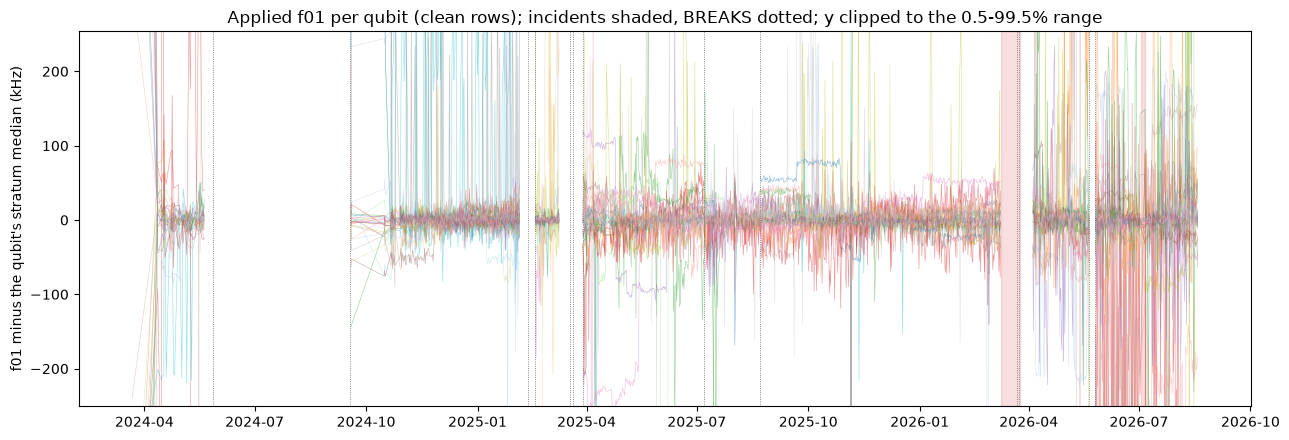

In [3]:
# Each qubit's f01 against its own median in the stratum (kHz)
stratum_median = clean.groupby(SER)["y"].transform("median")
look = clean.assign(yc=(clean["y"] - stratum_median) / 1e3)
look = look.groupby(SER).filter(lambda g: len(g) >= MIN_N)

# The scale of things: where f01 sits, the typical run-to-run move, and the in-stratum range
f01_ghz = clean.groupby("qubit")["y"].median() / 1e9
step_khz = (
    methods.lag_pairs(clean, SER, 1, col="y", cuts=CUTS)
    .groupby("qubit")["d"]
    .apply(lambda d: d.abs().median() / 1e3)
)
range_khz = look.groupby(SER)["yc"].apply(lambda y: y.quantile(0.95) - y.quantile(0.05))

print(
    f"median f01 per qubit: {f01_ghz.min():.4f} to {f01_ghz.max():.4f} GHz "
    f"(median {f01_ghz.median():.4f})"
)
print(
    f"median |change from the previous run| per qubit: "
    f"{step_khz.min():.3g} to {step_khz.max():.3g} kHz "
    f"(median {step_khz.median():.3g})"
)
print(
    f"5-95% range of f01 within a stratum, per qubit and stratum: "
    f"{range_khz.min():.3g} to {range_khz.max():.3g} kHz "
    f"(median {range_khz.median():.3g})"
)

# The traces, one line per qubit and stratum
fig, ax = plt.subplots(figsize=(13, 4.5))
cmap = plt.get_cmap("tab20")
for (q, _), g in look.groupby(SER):
    ax.plot(g["t"], g["yc"], lw=0.4, alpha=0.5, color=cmap(q % 20))

# Incidents shaded, breaks dotted
for inc in periods.INCIDENTS:
    ax.axvspan(*inc.period, color="tab:red", alpha=0.15)
for b in periods.BREAKS:
    ax.axvline(b.at, color="0.4", lw=0.6, ls=":")

# Clip y to the 0.5 to 99.5% range, or a few large moves would flatten everything
ax.set_ylim(*look["yc"].quantile([0.005, 0.995]))
ax.set_ylabel("f01 minus the qubit's stratum median (kHz)")
ax.set_title(
    "Applied f01 per qubit (clean rows); incidents shaded, BREAKS dotted; "
    "y clipped to the 0.5-99.5% range"
)

fig.tight_layout()
fig.savefig(FIG / "d1a_f01_traces.png", dpi=150)
print(f"saved {(FIG / 'd1a_f01_traces.png').relative_to(REPO_ROOT)}")
plt.show()

**Results.**

- The cuts are 2 incident starts (2026-03-09 08:45 and 2026-07-02 08:45) and 7 untracked DS2 writes that touched calibrate_1q, from 2025-02-12 13:40 to 2026-07-05 21:25.
- There are 37,882 applied f01 rows on 33 qubits and 1,278 runs, from 2024-03-21 to 2026-08-18. We leave out 260 incident, 255 f01 flag and 510 settling rows. That leaves 37,057 clean rows, and 34,010 of them have a B3c σ.
- The clean rows fall into 16 segments in 12 strata. The cuts split strata 3, 9 and 13.
- Most runs start in the 08 UTC hour (591) or the 19 UTC hour (527). A day with a run has a median of 2 runs.
- Strata hold 3 runs (stratum 5) to 391 runs (stratum 9), on 29 or 30 qubits (33 in stratum 0). Clean rows in stratum 11 start on 2026-04-04.
- Strata 0, 3, 5, 6 and 12 have no B3c noise row. Elsewhere the centred σ is 3.17 to 5.83 kHz and the fit sd 2.15 to 4.08 kHz (median per stratum).
- The qubits sit between 4.2364 and 4.5297 GHz (median 4.3783).
- The median change between runs is 3.17 to 64 kHz per qubit (median 4.3 kHz).
- Within a stratum, the 5 to 95% range of a qubit's f01 is 5.41 kHz to 25.6 MHz (median 36.5 kHz).


## 2. Is the run-to-run change shared?

This is the most direct form of the question. When one qubit's f01 changes from one run to the next, how much of that change does the rest of the chip make too?

We take lag-1 differences per qubit within each stratum (`methods.lag_pairs`). Pairs are at most 36 h apart and never span a cut. We put them in a panel of runs by qubits and centre each qubit on its median. A qubit needs MIN_N runs, and a chip median needs MIN_UNITS qubits.

The main measure is the common-mode share. It is the squared ratio of two spreads:

$$
\text{share} = \left( \frac{\text{spread of the chip median}}{\text{typical spread of one qubit}} \right)^2 .
$$

Unrelated qubits give a small share by chance, because their median is never exactly zero. So we compare each share with a null (`methods.common_mode_share`, as C1). The null shifts each qubit's series by its own random offset. Each qubit keeps its own changes, but the timing between qubits is lost.

We also give $R^2$, the squared correlation between a qubit's change and the chip median, as a median over qubits. r2_own keeps the qubit in the chip median, which makes the shared part look slightly larger. r2_loo leaves it out.

Last, share_above_null_of_signal removes both the chance level and the noise. Write $v_q$ for the variance of qubit $q$'s change and $\sigma_q$ for its noise σ. Each difference holds two noisy values, so noise adds $2\sigma_q^2$ to $v_q$, and

$$
\text{share above null of signal} = \frac{(\text{share} - \text{null median}) \cdot \operatorname{median}_q v_q}{\operatorname{median}_q \left( v_q - 2\sigma_q^2 \right)} .
$$

We compute it with both noise levels from section 1. The centred σ leaves less signal, so it gives the high end of this fraction. The fit sd (columns ending in _fit) gives the low end. The fraction is missing where the noise is larger than the change.


In [4]:
def panel(p: pd.DataFrame, col: str = "d", index: str = "run_0") -> pd.DataFrame:
    """Runs x qubits of col, centred per qubit on its median.

    Qubits with fewer than MIN_N values are dropped.
    """
    m = p.pivot_table(index=index, columns="qubit", values=col, aggfunc="first")
    m = m.loc[:, m.notna().sum() >= MIN_N]
    return m - m.median()


def r2_median(m: pd.DataFrame) -> tuple[float, float]:
    """Median over qubits of R2 between a qubit and the per-run chip median.

    r2_own keeps the qubit in the chip median, r2_loo leaves it out. Only runs with
    MIN_UNITS or more qubits count.
    """
    x = m.to_numpy(float)
    x = x[np.isfinite(x).sum(axis=1) >= MIN_UNITS]

    own, loo = [], []
    with warnings.catch_warnings():
        # All-NaN rows in the leave-one-out median
        warnings.simplefilter("ignore", RuntimeWarning)
        chip = np.nanmedian(x, axis=1)

        for j in range(x.shape[1]):
            ok = np.isfinite(x[:, j])
            if ok.sum() < MIN_N:
                continue

            # The chip median without qubit j
            rest = np.nanmedian(np.delete(x[ok], j, axis=1), axis=1)
            fin = np.isfinite(rest)

            own.append(np.corrcoef(x[ok, j], chip[ok])[0, 1] ** 2)
            loo.append(np.corrcoef(x[ok, j][fin], rest[fin])[0, 1] ** 2)

    return float(np.nanmedian(own)), float(np.nanmedian(loo))


def chip_local(m: pd.DataFrame) -> tuple[pd.Series, pd.DataFrame]:
    """Per-run chip median and each qubit's local residual from it.

    Only runs with MIN_UNITS or more qubits count.
    """
    c = m[m.notna().sum(axis=1) >= MIN_UNITS].median(axis=1)
    return c, m.loc[c.index].sub(c, axis=0)


def shares(df: pd.DataFrame, lag: int, cuts=CUTS) -> pd.DataFrame:
    """Common-mode share, R2 and the chip and local spreads of the lag differences, per stratum."""
    p = methods.lag_pairs(df, SER, lag, col="y", cuts=cuts)

    out = {}
    for st, g in p.groupby("stratum"):
        # Skip stratum-lags with too few independent differences or too few qubits
        m = panel(g)
        if len(m) < max(MIN_N, MIN_INDEP * lag) or m.shape[1] < MIN_UNITS:
            continue

        cm = methods.common_mode_share(m, MIN_UNITS)
        own, loo = r2_median(m)
        c, loc = chip_local(m)

        # A qubit's change variance
        var_q = m.apply(methods.rsd) ** 2
        row = {
            "runs": len(m),
            "qubits": m.shape[1],
            "qubit_sd_kHz": np.sqrt(var_q.median()) / 1e3,
            "chip_sd_kHz": methods.rsd(c) / 1e3,
            "local_sd_kHz": loc.apply(methods.rsd).median() / 1e3,
            "share": cm["share"],
            "null_median": cm["null_median"],
            "null_q95": cm["null_q95"],
            "p": cm["p"],
            "r2_own": own,
            "r2_loo": loo,
        }

        # For each noise level: the part of the change variance that isn't noise
        # (each difference holds two noisy values), and the shared part above chance
        # as a fraction of it
        for col, tag in [("sigma", ""), ("sigma_fit", "_fit")]:
            sigma_q = df[df["stratum"] == st].groupby("qubit")[col].first()
            s2 = sigma_q.reindex(m.columns) ** 2
            signal = (var_q - 2 * s2).median()
            if signal > 0:
                above_null = (cm["share"] - cm["null_median"]) * var_q.median() / signal
            else:
                above_null = np.nan
            row[f"noise_sd{tag}_kHz"] = np.sqrt(s2.median()) / 1e3
            row[f"share_above_null_of_signal{tag}"] = above_null

        out[st] = row

    out = pd.DataFrame(out).T
    return out.loc[sorted(out.index, key=series.stratum_order)]


# Every lag at once; section 3 reads the rest
sh = {L: shares(clean, L) for L in LAGS}

# Lag 1 per stratum, and its median over strata
median_cols = [
    "share",
    "null_median",
    "share_above_null_of_signal",
    "share_above_null_of_signal_fit",
    "r2_own",
    "r2_loo",
]
lag1_median = sh[1][median_cols].median().rename("median over strata").to_frame().T

print("lag 1 run, per stratum (sd in kHz; share and R2 as fractions):")
with pd.option_context("display.float_format", "{:.4g}".format):
    display(sh[1])
    display(lag1_median)


lag 1 run, per stratum (sd in kHz; share and R2 as fractions):


,runs,qubits,qubit_sd_kHz,chip_sd_kHz,local_sd_kHz,share,null_median,null_q95,p,r2_own,r2_loo,noise_sd_kHz,share_above_null_of_signal,noise_sd_fit_kHz,share_above_null_of_signal_fit
0 (start),21,28,8.917,1.18,8.328,0.01752,0.03675,0.09642,0.8806,0.06526,0.02203,NaN,NaN,NaN,NaN
2 (2024-09-18),203,29,8.259,1.972,7.955,0.057,0.049,0.06218,0.1542,0.01572,0.003828,5.834,NaN,4.082,0.01506
4 (2025-02-17),34,30,6.118,1.276,5.181,0.04348,0.02973,0.05445,0.1493,0.04394,0.02415,3.176,0.04679,2.246,0.02416
7 (2025-03-28),192,30,6.155,1.326,5.989,0.04643,0.05109,0.06612,0.6965,0.02138,0.01272,3.166,-0.01501,2.164,-0.006222
8 (2025-07-07),90,30,6.097,1.171,5.825,0.03691,0.0392,0.0554,0.597,0.07608,0.03487,3.181,-0.005445,2.209,-0.003341
9 (2025-08-22),385,30,5.357,1.484,5.239,0.07691,0.0511,0.06294,0.004975,0.01883,0.007322,3.276,0.2146,2.152,0.04099
11 (2026-03-24),92,30,7.135,1.986,6.92,0.07757,0.05586,0.07693,0.05473,0.03779,0.01783,4.357,0.07276,2.559,0.02846
13 (2026-05-25),157,30,6.995,1.619,6.718,0.05363,0.042,0.05677,0.08458,0.01848,0.006113,4.276,0.1847,2.372,0.01775


,share,null_median,share_above_null_of_signal,share_above_null_of_signal_fit,r2_own,r2_loo
median over strata,0.05003,0.0455,0.05978,0.01775,0.02958,0.01528


**Results.**

- 8 strata have a lag-1 panel (0, 2, 4, 7, 8, 9, 11 and 13), with 21 to 385 runs and 28 to 30 qubits.
- share is 0.01752 (stratum 0) to 0.07757 (stratum 11). Its median over strata is 0.05003, against a null median of 0.0455.
- Only stratum 9 is above its null q95 (0.07691 against 0.06294, p 0.004975). Strata 11 and 13 come close (p 0.05473 and 0.08458). The other strata have p 0.1493 to 0.8806.
- r2_own is 0.01572 to 0.07608 (median 0.02958). r2_loo is 0.003828 to 0.03487 (median 0.01528).
- The chip median changes by 1.171 to 1.986 kHz and the local part by 5.181 to 8.328 kHz. A whole qubit changes by 5.357 to 8.917 kHz.
- With the fit sd, the shared part above chance is −0.006 to 0.041 of the change that isn't noise (median 0.0178).
- With the centred σ it is −0.015 to 0.215 (median 0.0598). The high values are in strata 9 (0.215) and 13 (0.185), where the centred σ leaves little signal at lag 1. In stratum 2 the centred σ is larger than the change, so there is no value.
- In absolute terms the shared part stays small: share is at most 0.026 above its null median (stratum 9).


## 3. Does the sharing grow with the lag?

A small share between consecutive runs doesn't settle the question. A shared mode could build up slowly, like a random walk over months, while the local part is fast noise. Then the share would rise with the lag. If both parts are bounded, the share stays flat.

We repeat section 2 at every lag in LAGS, from 1 run (half a day) to 28 runs (about two weeks), within each stratum. A lag-$L$ pair is at most $L \times 36$ h apart.

Lag-$L$ differences overlap. At $L = 28$, neighbouring pairs share 27 of their 28 steps, so 60 pairs give only about two independent differences. So a stratum and lag count only if they have at least MIN_INDEP non-overlapping differences (pairs divided by $L$). The share null keeps each qubit's autocorrelation, so its q95 widens at long lags. The spreads and slopes have no such check. Section 6 covers longer timescales through the levels.

chip_sd is the robust sd of the chip median's change. local_sd is the robust sd of a qubit's change minus the chip median, as a median over qubits. To see how each part grows, we fit the log of its variance $D(L)$ against $\log L$:

$$
\log D(L) = a + b \log L .
$$

A slope $b = 1$ is a random walk, and $b = 0$ is a series that has stopped growing. local_signal removes the noise $2\sigma^2$ from the local variance before the fit, using the lags where what is left is positive. We fit it with both noise levels (local_signal and local_signal_fit). Removing more noise takes more off the short lags than the long ones, so the centred σ gives the steeper slope. The chip median's noise is about $1/N$ of a qubit's for $N$ qubits, so we don't correct it. A stratum gets a slope only if it has every lag in LAGS.

We don't test the lag-1 autocorrelation of the changes on its own. It follows from the lag 1 and lag 2 variances, $\rho = D(2) / 2D(1) - 1$, and noise alone pulls it towards −0.5.


In [5]:
lag_tab = pd.concat(sh, names=["lag", "stratum"])

# Pairs per stratum and lag, and how many non-overlapping differences that is
n_pairs = lag_tab["runs"].astype(int).unstack("lag")
print(f"pairs per stratum and lag (kept: at least {MIN_INDEP} x lag and {MIN_N})")
display(n_pairs.loc[sorted(n_pairs.index, key=series.stratum_order)])

# One table per column: strata down, lags across
lag_cols = [
    "share",
    "null_median",
    "share_above_null_of_signal",
    "share_above_null_of_signal_fit",
    "r2_loo",
    "chip_sd_kHz",
    "local_sd_kHz",
]
with pd.option_context("display.float_format", "{:.3g}".format):
    for col in lag_cols:
        t = lag_tab[col].astype(float).unstack("lag")
        print(col)
        display(t.loc[sorted(t.index, key=series.stratum_order)])


pairs per stratum and lag (kept: at least 5 x lag and 20)


lag,1,2,4,7,14,28
stratum,,,,,,
0 (start),21.0,20.0,22.0,NaN,NaN,NaN
2 (2024-09-18),203.0,200.0,202.0,199.0,192.0,179.0
4 (2025-02-17),34.0,33.0,31.0,NaN,NaN,NaN
7 (2025-03-28),192.0,190.0,187.0,184.0,177.0,163.0
8 (2025-07-07),90.0,89.0,87.0,84.0,77.0,NaN
9 (2025-08-22),385.0,382.0,376.0,367.0,346.0,315.0
11 (2026-03-24),92.0,91.0,89.0,86.0,79.0,NaN
13 (2026-05-25),157.0,155.0,151.0,145.0,131.0,NaN


share


lag,1,2,4,7,14,28
stratum,,,,,,
0 (start),0.0175,0.0414,0.0432,NaN,NaN,NaN
2 (2024-09-18),0.057,0.0462,0.0654,0.0834,0.0532,0.0856
4 (2025-02-17),0.0435,0.037,0.0552,NaN,NaN,NaN
7 (2025-03-28),0.0464,0.0452,0.057,0.0424,0.0248,0.0523
8 (2025-07-07),0.0369,0.0413,0.0414,0.0665,0.0243,NaN
9 (2025-08-22),0.0769,0.0725,0.0706,0.0749,0.0689,0.0885
11 (2026-03-24),0.0776,0.104,0.0808,0.0654,0.0531,NaN
13 (2026-05-25),0.0536,0.0516,0.0702,0.0619,0.0648,NaN


null_median


...

lag,1,2,4,7,14,28
stratum,,,,,,
0 (start),0.022,0.0206,0.0201,NaN,NaN,NaN
2 (2024-09-18),0.00383,0.00367,0.00278,0.00408,0.00483,0.00654
4 (2025-02-17),0.0241,0.0291,0.0119,NaN,NaN,NaN
7 (2025-03-28),0.0127,0.00433,0.00641,0.00615,0.0133,0.0187
8 (2025-07-07),0.0349,0.121,0.0711,0.088,0.121,NaN
9 (2025-08-22),0.00732,0.00591,0.00952,0.0126,0.0164,0.0068
11 (2026-03-24),0.0178,0.0321,0.0264,0.0123,0.0402,NaN
13 (2026-05-25),0.00611,0.00651,0.0163,0.00585,0.0141,NaN


chip_sd_kHz


lag,1,2,4,7,14,28
stratum,,,,,,
0 (start),1.18,2,2.41,NaN,NaN,NaN
2 (2024-09-18),1.97,1.93,2.26,2.42,2.25,2.81
4 (2025-02-17),1.28,1.1,1.34,NaN,NaN,NaN
7 (2025-03-28),1.33,1.41,1.6,1.79,1.8,3.27
8 (2025-07-07),1.17,1.34,1.39,1.84,1.2,NaN
9 (2025-08-22),1.48,1.49,1.54,1.7,1.76,2.27
11 (2026-03-24),1.99,2.28,2.61,2.99,3.24,NaN
13 (2026-05-25),1.62,1.93,2.29,2.55,2.8,NaN


local_sd_kHz


lag,1,2,4,7,14,28
stratum,,,,,,
0 (start),8.33,10.2,10,NaN,NaN,NaN
2 (2024-09-18),7.95,8.2,7.45,8.93,10.2,9.87
4 (2025-02-17),5.18,6.04,5.76,NaN,NaN,NaN
7 (2025-03-28),5.99,6.56,6.64,8.02,10.9,12.5
8 (2025-07-07),5.82,6.4,6.34,6.99,7.47,NaN
9 (2025-08-22),5.24,5.2,5.32,5.88,6.43,7.23
11 (2026-03-24),6.92,7.83,9.11,10.1,13.5,NaN
13 (2026-05-25),6.72,8.47,8.43,9.5,10.2,NaN


In [6]:
# Log-variance slope on log lag, for strata that have every lag in LAGS
full = lag_tab.groupby("stratum").filter(lambda g: len(g) == len(LAGS))


def signal_slope(log_lag: np.ndarray, local_var: pd.Series, noise_sd: pd.Series) -> tuple[float, int]:
    """Slope of the local variance with the noise 2 sigma^2 taken off, and the lags it uses.

    Needs at least 3 lags where the signal stays positive.
    """
    signal = local_var - 2 * noise_sd.astype(float) ** 2
    pos = (signal > 0).to_numpy()
    if pos.sum() < 3:
        return np.nan, int(pos.sum())
    return np.polyfit(log_lag[pos], np.log(signal[pos]), 1)[0], int(pos.sum())


slopes = {}
for st, g in full.groupby("stratum"):
    log_lag = np.log(g.index.get_level_values("lag").to_numpy(float))

    # Chip and local variances, and the local one with the noise taken off (both noise levels)
    chip_var = g["chip_sd_kHz"].astype(float) ** 2
    local_var = g["local_sd_kHz"].astype(float) ** 2
    b_main, n_main = signal_slope(log_lag, local_var, g["noise_sd_kHz"])
    b_fit, n_fit = signal_slope(log_lag, local_var, g["noise_sd_fit_kHz"])

    slopes[st] = {
        "chip": np.polyfit(log_lag, np.log(chip_var), 1)[0],
        "local": np.polyfit(log_lag, np.log(local_var), 1)[0],
        "local_signal": b_main,
        "signal_lags": n_main,
        "local_signal_fit": b_fit,
        "signal_lags_fit": n_fit,
    }

slopes = pd.DataFrame(slopes).T
print(f"log-variance slope on log lag ({LAGS} runs): 1 random walk, 0 bounded")
with pd.option_context("display.float_format", "{:.3g}".format):
    display(slopes.loc[sorted(slopes.index, key=series.stratum_order)])


log-variance slope on log lag ([1, 2, 4, 7, 14, 28] runs): 1 random walk, 0 bounded


,chip,local,local_signal,signal_lags,local_signal_fit,signal_lags_fit
2 (2024-09-18),0.201,0.163,0.667,3,0.286,6
7 (2025-03-28),0.466,0.467,0.682,6,0.544,6
9 (2025-08-22),0.236,0.203,0.545,6,0.274,6


**Results.**

- All 8 strata pass at lags 1 to 4. Strata 0 and 4 drop out from lag 7. Only strata 2 (179 pairs), 7 (163 pairs) and 9 (315 pairs) reach lag 28.
- share stays between 0.0175 (stratum 0, lag 1) and 0.104 (stratum 11, lag 2). From lag 1 to lag 28 it goes from 0.057 to 0.0856 in stratum 2 (null median 0.065 at lag 28), from 0.0464 to 0.0523 in stratum 7 (0.0337) and from 0.0769 to 0.0885 in stratum 9 (0.0512).
- The shared part above chance doesn't grow with the lag. With the fit sd it is −0.011 to 0.079 across all lags, and 0.0306, 0.02 and 0.0448 at lag 28 in strata 2, 7 and 9. With the centred σ it is −0.015 to 0.215, and 0.0673, 0.0211 and 0.0578 at lag 28. The one exception is 3.77 in stratum 2 at lag 7, where the centred σ leaves almost no signal. Apart from that, the largest values are at lags 1 and 2.
- r2_loo is at most 0.121 (stratum 8, lags 2 and 14). Outside stratum 8 it is at most 0.0402.
- From lag 1 to lag 28, chip_sd goes from 1.97 to 2.81 kHz in stratum 2, from 1.33 to 3.27 kHz in stratum 7 and from 1.48 to 2.27 kHz in stratum 9. local_sd goes from 7.95 to 9.87, 5.99 to 12.5 and 5.24 to 7.23 kHz.
- The slopes $b$ in strata 2, 7 and 9 are 0.201, 0.466 and 0.236 for chip, and 0.163, 0.467 and 0.203 for local.
- With the noise taken out, the local slopes rise. They are 0.286, 0.544 and 0.274 with the fit sd (6 lags each), and 0.667, 0.682 and 0.545 with the centred σ (stratum 2 on 3 lags only). So the local signal sits between bounded and a random walk with either noise level.


## 4. Where does the chip-wide variance sit?

A flat share at every lag could also come from a few very large runs, if they dominate the variance at every lag. So we look at how the chip-wide variance is spread over runs. If it is spread over all runs, it is a steady common drift. If a few runs hold most of it, it comes from a few chip-wide events.

The register has two INCIDENTS in 2026: the thermal cycle, and 2026-07-02 to 07-05, which a DS2 rollback undid on 07-05 (A4, B1).

- **Chip-wide change per run.** This is the median of the qubits' lag-1 differences, in runs with MIN_UNITS or more qubits. We compute it on all rows (incident, flag and settling rows in, no strata, no cuts) and on the clean pairs from section 2.
- **Budget.** For each version we give the share of the sum of squares in the TOP largest runs and the RMS of the rest. We list the 10 largest runs with any register event within NEAR_EVENT.
- **Net change across each incident.** For each qubit we compare the last clean run before the start with the first run at or after the end. We do this twice: once allowing settling rows, and once with the first clean run. We give it in kHz and as $z$, in units of the qubit's σ before the incident.

C2 (section 4) measures the level steps at the breaks against a placebo, so we don't repeat them here. The figure shows the chip-wide change per run for both versions, on a symmetric log scale.


In [7]:
def chip_changes(df: pd.DataFrame, keys: list[str], cuts=()) -> pd.DataFrame:
    """Per-run chip median of the lag-1 differences (kHz), runs with MIN_UNITS or more qubits."""
    p = methods.lag_pairs(df, keys, 1, col="y", cuts=cuts)
    g = p.groupby("run_0")
    out = pd.DataFrame(
        {
            "t_0": g["t_0"].first(),
            "t_1": g["t_1"].first(),
            "qubits": g["d"].count(),
            "chip_kHz": g["d"].median() / 1e3,
        }
    )
    return out[out["qubits"] >= MIN_UNITS]


def events_between(t0, t1, pad=NEAR_EVENT) -> str:
    """Register labels from t0 - pad to t1 + pad."""
    e = EV[(EV["at"] >= t0 - pad) & (EV["at"] <= t1 + pad)]
    return "; ".join(dict.fromkeys(e["label"]))


# The chip-wide change per run, on the raw series and on the clean one
cc = {
    "all rows (incidents, flags, settling in; no cuts)": chip_changes(f, ["qubit"]),
    "clean (within strata, cut)": chip_changes(clean, SER, CUTS),
}

budget = {}
for name, c in cc.items():
    # How much of the sum of squares sits in the TOP largest runs
    ss = c["chip_kHz"] ** 2
    top = ss.nlargest(TOP).index
    budget[name] = {
        "runs": len(c),
        "top_share_of_ss": ss[top].sum() / ss.sum(),
        "rms_top_kHz": np.sqrt(ss[top].mean()),
        "rms_rest_kHz": np.sqrt(ss.drop(top).mean()),
        "rsd_kHz": methods.rsd(c["chip_kHz"]),
    }

    # The 10 biggest chip-wide changes, with whatever the register has nearby
    big = c.loc[c["chip_kHz"].abs().nlargest(10).index].copy()
    big["events"] = [events_between(a, b) for a, b in zip(big["t_0"], big["t_1"])]
    print(f"{name}: 10 largest chip-wide lag-1 changes")
    with pd.option_context("display.float_format", "{:.4g}".format):
        display(big)

print(f"chip-wide lag-1 change budget (top = the {TOP} largest runs):")
with pd.option_context("display.float_format", "{:.4g}".format):
    display(pd.DataFrame(budget).T)

all rows (incidents, flags, settling in; no cuts): 10 largest chip-wide lag-1 changes


,t_0,t_1,qubits,chip_kHz,events
run_0,,,,,
1210,2026-07-05 19:34:00,2026-07-05 21:54:09,14,6.322e+04,UNTRACKED_DS2; F01_FLAG end; INCIDENT end; DS4_GAP start
1202,2026-07-01 19:38:11,2026-07-02 08:45:41,30,-1.578e+04,INCIDENT start; DS4_GAP end; F01_FLAG start
1009,2026-03-10 08:45:17,2026-03-10 19:42:52,14,-1.395e+04,THERMAL_CYCLE start; INCIDENT start; F01_FLAG start; OUTAGE start
1204,2026-07-02 19:38:25,2026-07-03 08:45:41,14,-1.023e+04,INCIDENT start; DS4_GAP end; F01_FLAG start
1006,2026-03-08 19:42:41,2026-03-09 08:45:16,30,-9631,THERMAL_CYCLE start; INCIDENT start; F01_FLAG start
1007,2026-03-09 08:45:16,2026-03-09 19:42:45,30,-9471,THERMAL_CYCLE start; INCIDENT start; F01_FLAG start
1008,2026-03-09 19:42:45,2026-03-10 08:45:17,14,-9088,THERMAL_CYCLE start; INCIDENT start; F01_FLAG start; OUTAGE start
1011,2026-03-11 08:45:16,2026-03-11 19:43:57,14,-7379,INCIDENT start; F01_FLAG start; OUTAGE start
1203,2026-07-02 08:45:41,2026-07-02 19:38:25,30,-6118,INCIDENT start; DS4_GAP end; F01_FLAG start


clean (within strata, cut): 10 largest chip-wide lag-1 changes


,t_0,t_1,qubits,chip_kHz,events
run_0,,,,,
983,2026-02-25 08:45:16,2026-02-25 20:42:06,30,-11.74,UNTRACKED_DS2
569,2025-07-31 19:44:10,2025-08-01 08:45:23,30,9.231,
1043,2026-04-10 19:48:27,2026-04-11 08:45:17,30,7.457,
1077,2026-04-27 19:52:00,2026-04-28 08:45:17,30,-7.171,
1124,2026-05-21 20:26:57,2026-05-22 08:45:38,30,-6.949,UNTRACKED_DS2; BREAK 2026-05-21 DS3 openpulse_features added
165,2024-12-26 08:00:20,2024-12-26 19:52:48,29,-6.299,
1078,2026-04-28 08:45:17,2026-04-28 19:46:50,30,6.286,
1279,2026-08-09 13:37:47,2026-08-10 07:45:41,30,6.179,
987,2026-02-27 08:45:16,2026-02-27 19:38:00,30,6.016,UNTRACKED_DS2


chip-wide lag-1 change budget (top = the 5 largest runs):


,runs,top_share_of_ss,rms_top_kHz,rms_rest_kHz,rsd_kHz
"all rows (incidents, flags, settling in; no cuts)",1247,0.9392,3.045e+04,491.8,1.68
"clean (within strata, cut)",1206,0.09669,8.698,1.715,1.646


In [8]:
# Net change across each incident: the last clean run before it against the first run after it
base = f[~(f["incident"] | f["f01_flag"])]  # settling rows still in

net = []
for inc in periods.INCIDENTS:
    s, e = inc.period
    before = clean[clean["t"] < s].groupby("qubit").last()

    # Once with settling rows allowed, once with the first clean run
    for how, pool in [("first run after the end", base), ("first clean run after the end", clean)]:
        after = pool[pool["t"] >= e].groupby("qubit").first()
        d = (after["y"] - before["y"]).dropna()
        z = d / before["sigma"].reindex(d.index)

        net.append(
            {
                "incident": inc.what,
                "start": s,
                "end": e,
                "after": how,
                "t_before_last": before["t"].max(),
                "t_after_median": after["t"].reindex(d.index).median(),
                "qubits": len(d),
                "median_kHz": d.median() / 1e3,
                "share_negative": (d < 0).mean(),
                "min_kHz": d.min() / 1e3,
                "max_kHz": d.max() / 1e3,
                "median_abs_z": z.abs().median(),
            }
        )

print("net change across each incident (after minus the last clean run before the start):")
with pd.option_context("display.float_format", "{:.4g}".format):
    display(pd.DataFrame(net))


net change across each incident (after minus the last clean run before the start):


,incident,start,end,after,t_before_last,t_after_median,qubits,median_kHz,share_negative,min_kHz,max_kHz,median_abs_z
0,thermal cycle,2026-03-09 08:45:16,2026-03-24 14:45:52,first run after the end,2026-03-08 19:42:41,2026-03-24 14:45:52,30,-1225,0.6333,-8744,4119,685.5
1,thermal cycle,2026-03-09 08:45:16,2026-03-24 14:45:52,first clean run after the end,2026-03-08 19:42:41,2026-04-04 08:45:16,30,-1295,0.6333,-8698,4162,683.9
2,"chip-wide f01 shift, fridge state unknown (DS4 gap)",2026-07-02 08:45:41,2026-07-05 21:54:09,first run after the end,2026-07-01 19:38:11,2026-07-05 21:54:09,30,-0.8582,0.6333,-105.2,325.7,1.306
3,"chip-wide f01 shift, fridge state unknown (DS4 gap)",2026-07-02 08:45:41,2026-07-05 21:54:09,first clean run after the end,2026-07-01 19:38:11,2026-07-05 21:54:09,30,-0.8582,0.6333,-105.2,325.7,1.306


saved docs/figures/hypotheses/d1a_chip_f01.png


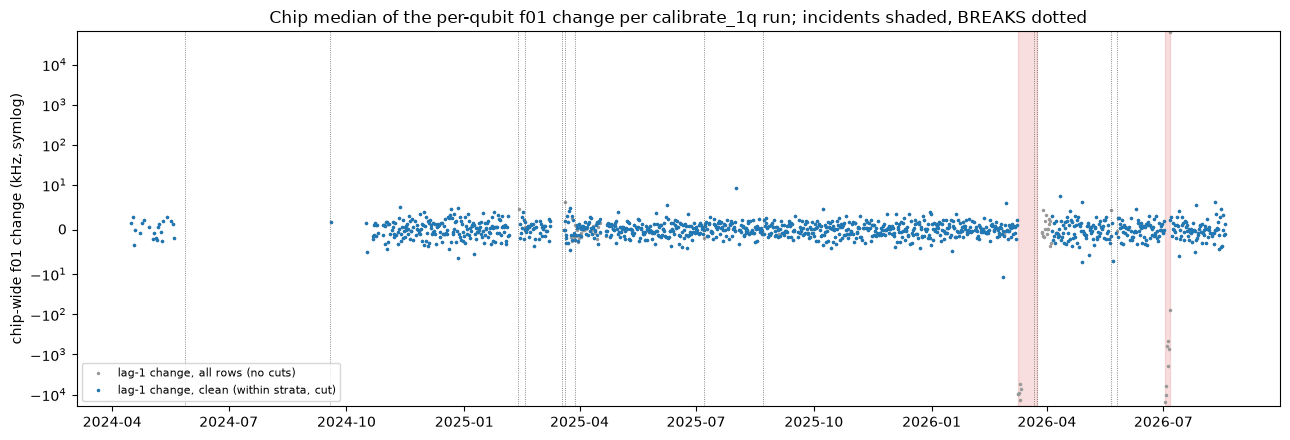

In [9]:
fig, ax = plt.subplots(figsize=(13, 4.5))
all_cc, clean_cc = cc.values()

# The chip-wide change per run, both ways
ax.plot(
    all_cc["t_1"],
    all_cc["chip_kHz"],
    ".",
    ms=3,
    color="0.6",
    label="lag-1 change, all rows (no cuts)",
)
ax.plot(
    clean_cc["t_1"],
    clean_cc["chip_kHz"],
    ".",
    ms=3,
    color="tab:blue",
    label="lag-1 change, clean (within strata, cut)",
)

# Incidents shaded, breaks dotted
for inc in periods.INCIDENTS:
    ax.axvspan(*inc.period, color="tab:red", alpha=0.15)
for b in periods.BREAKS:
    ax.axvline(b.at, color="0.4", lw=0.6, ls=":")

# Linear within +-10 kHz, log beyond
ax.set_yscale("symlog", linthresh=10)
ax.set_ylabel("chip-wide f01 change (kHz, symlog)")
ax.set_title(
    "Chip median of the per-qubit f01 change per calibrate_1q run; incidents shaded, BREAKS dotted"
)
ax.legend(loc="lower left", fontsize=8)

fig.tight_layout()
fig.savefig(FIG / "d1a_chip_f01.png", dpi=150)
print(f"saved {(FIG / 'd1a_chip_f01.png').relative_to(REPO_ROOT)}")
plt.show()


**Results.**

- All rows (1,247 runs): the 5 largest runs hold 0.9392 of the sum of squares. Their RMS is 30.45 MHz, against 491.8 kHz for the other runs. The robust sd is 1.68 kHz.
- The 10 largest all-row changes are 5.6 to 63.2 MHz in size. All fall on 2026-03-08 to 03-11 or 2026-07-01 to 07-05, each within NEAR_EVENT of an incident start or end. The largest is +63.22 MHz, from 2026-07-05 19:34 to 21:54 (14 qubits), at the incident end and an untracked DS2 write.
- Clean rows (1,206 runs): the 5 largest runs hold 0.09669 of the sum of squares. Their RMS is 8.698 kHz, against 1.715 kHz for the other runs. The robust sd is 1.646 kHz.
- The largest clean change is −11.74 kHz, from 2026-02-25 08:45 to 20:42, at an untracked DS2 write. 3 of the 10 largest have a register event within NEAR_EVENT, and each is an untracked DS2 write (2026-02-25, 2026-02-27 and 2026-05-21).
- Across the thermal cycle (30 qubits), the median net change is −1,225 kHz to the first run after the end (2026-03-24 14:45). It is −1,295 kHz to the first clean run (median 2026-04-04 08:45). 0.6333 of qubits go down, and the range is −8,744 to +4,119 kHz. The median $|z|$ is 685.5 and 683.9.
- Across 2026-07-02 to 07-05 (30 qubits), the median net change is −0.8582 kHz, with a range of −105.2 to +325.7 kHz. The median $|z|$ is 1.306, so the median qubit comes back to about 1.3 σ from where it was. Both versions use the same run (2026-07-05 21:54).


## 5. Does the sampling grid change the answer?

Shares from a daily series and from a sparser grid, such as the DS3 run days, are not directly comparable. So we check whether the grid changes the answer. The test window is FRAME_WINDOW, where DS3 logs drive frames that A3 checked against DS2.

We take the last applied f01 per qubit and UTC day inside the window, and its change from one day to the next. We score the changes with the $R^2$ pair and the common-mode share on two grids:

- **daily:** calendar days. A missing day breaks the chain.
- **DS3 days:** only days with a DS3 run, with changes between consecutive DS3 days.

We score each grid with all rows and with the incident and flag rows left out. We also print the 3 largest chip-wide daily changes in each case.


In [10]:
# The frame window, and the DS3 run days inside it
lo, hi = FRAME_WINDOW
ds3_days = pd.DatetimeIndex(sorted(load_runs()["created_at"].dt.floor("D").unique()))
ds3_days = ds3_days[(ds3_days >= lo) & (ds3_days < hi)]


def daily_last(df: pd.DataFrame) -> pd.DataFrame:
    """Days x qubits of the last applied f01 of each UTC day in the window."""
    d = df[(df["t"] >= lo) & (df["t"] < hi)].sort_values("t")
    d = d.assign(day=d["t"].dt.floor("D"))
    return d.groupby(["day", "qubit"])["y"].last().unstack()


all_days = pd.date_range(lo, hi - pd.Timedelta("1D"), freq="D")

row_sets = [
    ("all rows", f),
    ("incidents and flags left out", f[~(f["incident"] | f["f01_flag"])]),
]

win = {}
for rows_name, df in row_sets:
    dl = daily_last(df)

    # Two grids: every calendar day (a missing day breaks the chain), or DS3 run days only
    grids = {
        "daily": dl.reindex(all_days).diff(),
        "DS3 days": dl.reindex(ds3_days).dropna(how="all").diff(),
    }

    for grid, changes in grids.items():
        # Qubits with MIN_N changes, centred per qubit
        m = changes.loc[:, changes.notna().sum() >= MIN_N]
        m = m - m.median()

        own, loo = r2_median(m)
        cm = methods.common_mode_share(m, MIN_UNITS)

        # The 3 largest chip-wide daily changes
        c, _ = chip_local(m)
        top = c.abs().nlargest(3).index
        largest = "; ".join(f"{d:%m-%d} {c[d] / 1e3:+.4g}" for d in top)

        win[(grid, rows_name)] = {
            "days": len(changes),
            "increments": int(m.notna().sum().sum()),
            "r2_own": own,
            "r2_loo": loo,
            "share": cm["share"],
            "null_median": cm["null_median"],
            "p": cm["p"],
            "largest_chip_kHz": largest,
        }

print(
    f"frame window {lo:%Y-%m-%d} to {hi - pd.Timedelta('1D'):%Y-%m-%d}; "
    f"DS3 run days in it: {len(ds3_days)}"
)
with pd.option_context("display.float_format", "{:.3g}".format):
    display(pd.DataFrame(win).T)

frame window 2026-05-21 to 2026-08-16; DS3 run days in it: 69


,,days,increments,r2_own,r2_loo,share,null_median,p,largest_chip_kHz
daily,all rows,88,2502,0.985,0.985,0.0494,0.0364,0.164,07-05 +5.382e+04; 07-02 -2.141e+04; 07-03 -1.466e+04
DS3 days,all rows,69,2040,0.0244,0.0129,0.0488,0.0377,0.154,08-10 +6.782; 07-15 -5.164; 07-30 -4.775
daily,incidents and flags left out,88,2430,0.0253,0.0154,0.0447,0.0353,0.169,05-22 -6.943; 08-10 +6.49; 07-13 -5.929
DS3 days,incidents and flags left out,69,2040,0.0244,0.0129,0.0488,0.0377,0.154,08-10 +6.782; 07-15 -5.164; 07-30 -4.775


**Results.**

- The window has 88 calendar days and 69 DS3 run days.
- Daily, all rows: r2_own 0.985 and r2_loo 0.985. share is 0.0494 (null median 0.0364, p 0.164). The largest chip-wide changes are on 07-05 (+53.82 MHz), 07-02 (−21.41 MHz) and 07-03 (−14.66 MHz).
- Daily, incident and flag rows out: r2_own 0.0253 and r2_loo 0.0154. share is 0.0447 (null median 0.0353, p 0.169). The largest changes are on 05-22 (−6.943 kHz), 08-10 (+6.49 kHz) and 07-13 (−5.929 kHz).
- DS3 days give the same result with or without those rows (2,040 changes): r2_own 0.0244 and r2_loo 0.0129. share is 0.0488 (null median 0.0377, p 0.154). The largest changes are on 08-10 (+6.782 kHz), 07-15 (−5.164 kHz) and 07-30 (−4.775 kHz).
- So the incident rows decide the answer, not the grid. This repeats section 4 on a daily scale.


## 6. Is there a slow shared level?

Sections 2 to 5 use changes. A shared level that moves a few kHz over weeks barely shows in them. So here we look at the levels. We ask whether the chip median level is more coherent than unrelated qubits would give, and if so, whether the shared part is slow or fast.

We build panels of runs by qubits from the clean levels and score them as in section 2:

- **per segment:** each qubit centred within the segment (section 1), for every segment with MIN_N runs;
- **before 2026, pooled:** all runs before 2026-01-01, with each qubit centred within each segment.

We centre within segments, not strata, because a stratum can contain a chip-wide step at a cut. Inside one panel, such a step would count as a shared level. The null keeps each qubit's autocorrelation, so a qubit that wanders slowly on its own doesn't count as shared.

Centring per segment does not remove a single run that sits far from the rest without a cut. $R^2$ is not robust, so one such run can push it close to 1, while the share, which uses robust spreads, stays small. So we read the share first and $R^2$ only next to it. For each panel we also give the run where the chip median is furthest from 0, so such a run is easy to find.

To separate slow from fast, we take the chip median level per run in each segment at least MIN_SPAN_DAYS long. We split it into a slow part, the centred rolling mean over SLOW, and a fast part, the rest. The median of unrelated qubits also has a slow part. So we compare the slow sd with the same circular-shift null (N_NULL draws).


In [11]:
def level_share(df: pd.DataFrame, centre_by: list[str]) -> dict:
    """Common-mode share and R2 of the clean levels, each qubit centred within centre_by."""
    d = df.assign(yc=df["y"] - df.groupby(centre_by)["y"].transform("median"))
    m = panel(d, col="yc", index="run")

    cm = methods.common_mode_share(m, MIN_UNITS)
    own, loo = r2_median(m)
    c, loc = chip_local(m)

    # The run where the chip median is furthest from 0
    top = c.abs().idxmax()

    return {
        "runs": len(m),
        "qubits": m.shape[1],
        "chip_sd_kHz": methods.rsd(c) / 1e3,
        "local_sd_kHz": loc.apply(methods.rsd).median() / 1e3,
        "share": cm["share"],
        "null_median": cm["null_median"],
        "null_q95": cm["null_q95"],
        "p": cm["p"],
        "r2_own": own,
        "r2_loo": loo,
        "furthest_run": d.loc[d["run"] == top, "t"].iloc[0],
        "furthest_kHz": c[top] / 1e3,
    }


def by_start(groups):
    """Groupby items in time order."""
    return sorted(groups, key=lambda kv: kv[1]["t"].min())


lvl = {}

# Per segment
for sg, g in by_start(clean.groupby("seg")):
    if g["run"].nunique() >= MIN_N:
        lvl[("segment", sg)] = level_share(g, ["qubit"])

# Before 2026, pooled, each qubit centred within each segment
pre = clean[clean["t"] < pd.Timestamp("2026-01-01")]
lvl[("before 2026, pooled", "centred per qubit and segment")] = level_share(pre, ["qubit", "seg"])

lvl = pd.DataFrame(lvl).T
with pd.option_context("display.float_format", "{:.3g}".format):
    display(lvl)


runs qubits chip_sd_kHz local_sd_kHz  share null_median null_q95       p r2_own r2_loo         furthest_run furthest_kHz
segment             0 (start) c0                    32     29        2.08         12.3 0.0241      0.0224   0.0869   0.453  0.994  0.993  2024-03-21 17:03:19         -325
                    2 (2024-09-18) c0              209     29        2.04         8.15 0.0623      0.0527   0.0776   0.184 0.0166 0.0135  2024-10-21 12:02:39        -6.27
                    4 (2025-02-17) c2               37     30       0.876          3.9 0.0464      0.0262   0.0486  0.0746 0.0377 0.0128  2025-03-07 19:45:31         2.32
                    7 (2025-03-28) c3              195     30         2.1         13.9 0.0221      0.0199   0.0448   0.378 0.0479 0.0262  2025-04-17 08:45:22         6.62
                    8 (2025-07-07) c3               92     30        1.43         6.02 0.0522       0.039   0.0626   0.164  0.105 0.0747  2025-08-01 08:45:23         20.1
                    9 (2025-08-22) c3               25     30       0.444         3.74 0.0129      0.0312   0.0659   0.925 0.0474 0.0363  2025-08-23 08:45:23         -2.8
                    9 (2025-08-22) c4              345     30        2.55         9.74 0.0629      0.0319   0.0557  0.0448  0.104 0.0747  2026-02-26 08:45:36        -21.9
                    9 (2025-08-22) c5               21     30        0.63         3.94 0.0261      0.0281   0.0711   0.527  0.112  0.134  2026-02-27 08:45:16        -5.82
                    11 (2026-03-24) c7              93     30        4.06         12.4 0.0956      0.0301   0.0622 0.00498 0.0688 0.0439  2026-04-04 19:44:57         13.5
                    13 (2026-05-25) c7              74     30        1.75         6.11 0.0697       0.042   0.0728  0.0796 0.0496 0.0293  2026-06-18 08:45:41        -5.07
                    13 (2026-05-25) c9              86     30        2.44         10.8 0.0352      0.0183   0.0304  0.0199 0.0928 0.0779  2026-08-11 07:47:40         8.46
before 2026, pooled centred per qubit and segment  857     30         1.8         7.64 0.0496      0.0341   0.0405 0.00498  0.474  0.472  2024-03-21 17:03:19         -410

In [12]:
def chip_level(x: np.ndarray, t: pd.DatetimeIndex) -> pd.Series:
    """Per-run chip median of a runs x qubits array, indexed by time.

    Only runs with MIN_UNITS or more qubits count.
    """
    keep = np.isfinite(x).sum(axis=1) >= MIN_UNITS
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        return pd.Series(np.nanmedian(x[keep], axis=1), index=t[keep])


def slow_fast(c: pd.Series) -> tuple[pd.Series, pd.Series]:
    """Slow part of c (centred rolling mean over SLOW) and the fast remainder."""
    slow = c.rolling(SLOW, center=True, min_periods=10).mean()
    return slow, c - slow


# Its own generator, so the section 7 draws don't depend on this cell
rng_slow = np.random.default_rng(1)

# Each qubit centred within its segment
seg_median = clean.groupby(["qubit", "seg"])["y"].transform("median")
seg_lvl = clean.assign(yc=clean["y"] - seg_median)

split = {}
for sg, g in by_start(seg_lvl.groupby("seg")):
    # Runs x qubits; only segments long enough and with enough qubits
    m = g.pivot_table(index="t", columns="qubit", values="yc", aggfunc="first")
    m = m.loc[:, m.notna().sum() >= MIN_N]
    span = (m.index.max() - m.index.min()) / pd.Timedelta("1D")
    if span < MIN_SPAN_DAYS or m.shape[1] < MIN_UNITS:
        continue

    # The chip level, and its slow and fast parts
    x = m.to_numpy(float)
    c = chip_level(x, m.index)
    slow, fast = slow_fast(c)

    # Null: each qubit shifted by its own random offset, so it keeps its own wander
    # but loses the timing against the other qubits
    null = []
    for _ in range(N_NULL):
        shifted = [np.roll(col, rng_slow.integers(len(col))) for col in x.T]
        null_slow = slow_fast(chip_level(np.column_stack(shifted), m.index))[0]
        null.append(null_slow.std())
    null = np.array(null)

    split[sg] = {
        "runs": len(c),
        "qubits": m.shape[1],
        "span_days": span,
        "chip_sd_kHz": c.std() / 1e3,
        "slow_sd_kHz": slow.std() / 1e3,
        "fast_sd_kHz": fast.std() / 1e3,
        "slow_share_of_var": slow.var() / c.var(),
        "null_slow_sd_median_kHz": np.median(null) / 1e3,
        "null_slow_sd_q95_kHz": np.quantile(null, 0.95) / 1e3,
        "p": methods.perm_p(null, slow.std()),
    }

split = pd.DataFrame(split).T
print(
    f"chip median level split into slow (rolling {SLOW}) and fast parts, "
    f"segments of {MIN_SPAN_DAYS}+ days; null from {N_NULL} circular shifts per qubit"
)
with pd.option_context("display.float_format", "{:.3g}".format):
    display(split)


chip median level split into slow (rolling 30D) and fast parts, segments of 90+ days; null from 200 circular shifts per qubit


,runs,qubits,span_days,chip_sd_kHz,slow_sd_kHz,fast_sd_kHz,slow_share_of_var,null_slow_sd_median_kHz,null_slow_sd_q95_kHz,p
2 (2024-09-18) c0,209,29,139,2.25,1.22,1.8,0.296,0.626,1.26,0.0647
7 (2025-03-28) c3,195,30,100,2.17,1,1.85,0.214,1.02,2.06,0.522
9 (2025-08-22) c4,345,30,176,2.77,1.55,2.11,0.313,0.889,1.64,0.0846


**Results.**

- 11 segments have MIN_N runs or more. chip_sd is 0.444 to 4.06 kHz and local_sd 3.74 to 13.9 kHz.
- share is above its null q95 in 3 of them: 7 c4 (0.0629 against 0.0557, p 0.0448), 9 c7 (0.0956 against 0.0622, p 0.00498) and 11 c9 (0.0352 against 0.0304, p 0.0199). The other 8 have p 0.0746 to 0.925.
- r2_own is 0.0166 to 0.112, except in 0 c0, where it is 0.994. There the furthest run is the first one, 2024-03-21 17:03, at −325 kHz. So one run makes that $R^2$, and its share (0.0241) is at chance (p 0.453).
- Elsewhere the furthest runs are −21.9 to +20.1 kHz from 0. The largest are 2026-02-26 08:45 (7 c4, −21.9 kHz), just before the untracked DS2 write at 19:05, and 2025-08-01 08:45 (6 c3, +20.1 kHz).
- Before 2026, pooled (857 runs): share is 0.0496 against a null median of 0.0341 and q95 of 0.0405 (p 0.00498). r2_own is 0.474, but the furthest run is again 2024-03-21 17:03 (−410 kHz). chip_sd is 1.8 kHz against a local_sd of 7.64 kHz.
- Three segments are 90 days or longer: 2 c0 (209 runs, 139 days), 7 c3 (195 runs, 100 days) and 9 c4 (345 runs, 176 days).
- The slow part holds 0.296, 0.214 and 0.313 of the chip level's variance in these segments. Its sd is 1.22, 1 and 1.55 kHz. The null medians are 0.626, 1.02 and 0.889 kHz, and the null q95s are 1.26, 2.06 and 1.64 kHz.
- So p is 0.0647, 0.522 and 0.0846, and no slow part is above its null q95.


## 7. Does the fridge drive the shared part?

The fridge is the obvious shared cause, because every qubit sits on the same mixing chamber. A fit over the whole record would mostly fit the thermal cycle, where both series move by orders of magnitude. So we compare them only on settled stretches, and we look at the incidents separately.

We follow the B1 and C3 rules for MIX. We use only settled MIX, centred per epoch, with a time term inside each epoch. No epoch reaches 30 blocks (C3, section 2), so we use a block bootstrap. Blocks are 28 days in epochs 0 and 1 and 14 days in epoch 3 (C3, section 1).

- **Settled MIX.** B1's noise rows give the settled window of each epoch. We take the cold rows inside those windows and their daily medians in mK. Epoch 2 has no noise row, so it drops out.
- **Chip f01.** We centre each qubit's clean level, take the per-run chip median (MIN_UNITS qubits) and then its daily median in kHz.
- **Per epoch.** We residualise both series on an intercept, the days since the epoch's first joined day and group dummies. From the residuals we give:
  - $r$, with a moving-block bootstrap interval (N_BOOT draws, calendar-day blocks);
  - p_shift, from circular shifts of the MIX residual by at least one block;
  - r_2day, the correlation of 2-day differences;
  - the OLS slope in kHz per mK.

  With so few blocks, the interval and p_shift are rough. A short epoch also allows only a few distinct shifts (the shifts column).
- **Two versions.** We centre and residualise per stratum, and again per segment. Segments remove level steps at the cuts. The cuts inside epoch 0 are DS2 writes, and a step there has nothing to do with the fridge. But each short segment also takes out any slow change inside it, which pulls $r$ towards 0. If the two versions agree, the cuts don't matter.
- **Many channels at once.** We regress chip f01 on every fridge channel with daily medians on at least 90% of the joined days, for both versions. The channels are standardised and the epochs pooled. We compare the in-sample $R^2$ with the $R^2$ after circular shifts of the chip series (200 draws), and with $p/n$.
- **At the incidents.** We give the DS4 rows, the last reading before the start, and the MIX range from 1 day before to 1 day after.


In [13]:
# B1's settled epochs: one MIX noise row per epoch, with its settled window (UTC, no timezone)
nz = load_noise_floor()
nz = nz[(nz["source"] == "ds4") & (nz["param"] == MIX) & (nz["method"] == "lag1_robust_over_sqrt2")]
ep = nz.set_index(nz["regime"].str.removeprefix("epoch ").astype(int).rename("epoch"))[["start", "end"]]
print("B1 settled epochs (MIX noise rows):")
display(ep)

# The fridge on UTC with no timezone, as DS1
w = load_fridge()
w.index = w.index.tz_convert("UTC").tz_localize(None)
cold = cold_mask(w)

# Each cold row inside a settled window, tagged with its epoch
ep_of = pd.Series(np.nan, index=w.index)
for k, e in ep.iterrows():
    ep_of.loc[cold & (w.index >= e["start"]) & (w.index <= e["end"])] = k
settled = ep_of.notna()

# Daily medians of every channel over the settled rows
ws = w[settled]
day = ws.index.floor("D")
fr_day = ws.groupby(day).median()
fr_ep = ep_of[settled].groupby(day).max()
mix_day = (fr_day[MIX] * 1e3).rename("mix_mK")

# Two versions of the chip series: centred and residualised per stratum, or per segment
VARIANTS = {"stratum": "stratum", "segment": "seg"}


def chip_daily(by: str) -> pd.DataFrame:
    """Chip f01 per day (kHz): qubits centred within `by`, the per-run chip median, then the daily median."""
    cf = clean.assign(yc=clean["y"] - clean.groupby(["qubit", by])["y"].transform("median"))
    g = cf.groupby("run")
    cr = pd.DataFrame(
        {
            "t": g["t"].first(),
            "group": g[by].first(),
            "n": g["yc"].count(),
            "c": g["yc"].median() / 1e3,
        }
    )
    cr = cr[cr["n"] >= MIN_UNITS]
    return cr.groupby(cr["t"].dt.floor("D")).agg(chip_kHz=("c", "median"), group=("group", "first"))


# Days with both chip f01 and settled MIX, tagged by epoch, per version
J = {}
for v, by in VARIANTS.items():
    j = (
        chip_daily(by)
        .join(mix_day, how="inner")
        .join(fr_ep.rename("epoch"))
        .dropna(subset=["chip_kHz", "mix_mK", "epoch"])
    )
    j["epoch"] = j["epoch"].astype(int)
    J[v] = j
    print(f"{v}: joined settled days per epoch", j.groupby("epoch").size().to_dict(),
          "| groups per epoch", j.groupby("epoch")["group"].nunique().to_dict())


def resid(d: pd.DataFrame, col: str) -> pd.Series:
    """col residualised on an intercept, days since the first day and dummies for each group."""
    X = pd.get_dummies(d["group"], drop_first=True, dtype=float)
    X.insert(0, "days", (d.index - d.index[0]) / pd.Timedelta("1D"))
    X.insert(0, "one", 1.0)
    beta, *_ = np.linalg.lstsq(X.to_numpy(float), d[col].to_numpy(float), rcond=None)
    return d[col] - X.to_numpy(float) @ beta


# Correlation over the days where both are finite (NaN with fewer than 3)
def corr(a: np.ndarray, b: np.ndarray) -> float:
    ok = np.isfinite(a) & np.isfinite(b)
    return float(np.corrcoef(a[ok], b[ok])[0, 1]) if ok.sum() >= 3 else np.nan


res = {}
for k, B in BLOCK_DAYS.items():
    for v in VARIANTS:
        d = J[v][J[v]["epoch"] == k]
        if len(d) < MIN_N:
            continue

        # Residuals on a full calendar, so a missing day is a gap rather than a neighbour
        cal = pd.date_range(d.index[0], d.index[-1], freq="D")
        a = resid(d, "chip_kHz").reindex(cal).to_numpy()
        b = resid(d, "mix_mK").reindex(cal).to_numpy()
        r = corr(a, b)
        n = len(cal)

        # Moving-block bootstrap (wrapping), B-day blocks
        boot = []
        for _ in range(N_BOOT):
            starts = rng.integers(0, n, int(np.ceil(n / B)))
            blocks = [np.arange(s, s + B) % n for s in starts]
            idx = np.concatenate(blocks)[:n]
            boot.append(corr(a[idx], b[idx]))

        # Circular-shift null, shifts of at least one block
        if n > 2 * B:
            shifts = rng.integers(B, n - B, N_BOOT)
            null = np.array([corr(a, np.roll(b, s)) for s in shifts])
        else:
            null = np.array([np.nan])
        p_shift = (1 + (np.abs(null) >= abs(r)).sum()) / (1 + np.isfinite(null).sum())

        ok = np.isfinite(a) & np.isfinite(b)
        res[(k, v)] = {
            "days": int(ok.sum()),
            "span_days": n,
            "blocks": n / B,
            "shifts": max(n - 2 * B, 0),
            "groups": d["group"].nunique(),
            "chip_sd_kHz": np.nanstd(a),
            "mix_sd_mK": np.nanstd(b),
            "r": r,
            "r_lo": np.nanquantile(boot, 0.025),
            "r_hi": np.nanquantile(boot, 0.975),
            "p_shift": p_shift,
            "r_2day": corr(a[2:] - a[:-2], b[2:] - b[:-2]),
            "slope_kHz_per_mK": np.polyfit(b[ok], a[ok], 1)[0],
        }

res = pd.DataFrame(res).T.rename_axis(["epoch", "centred and residualised per"])
print(
    "chip f01 against settled MIX per epoch (residuals on intercept, time and stratum or segment "
    "dummies; block bootstrap 95% interval; shifts = distinct circular shifts):"
)
with pd.option_context("display.float_format", "{:.3g}".format):
    display(res)


B1 settled epochs (MIX noise rows):


,start,end
epoch,,
0,2025-08-03,2026-03-09 00:00:00
1,2026-04-04,2026-06-11 18:00:00
3,2026-07-08,2026-09-03 12:00:00


stratum: joined settled days per epoch {0: 218, 1: 68, 3: 42} | groups per epoch {0: 2, 1: 3, 3: 1}
segment: joined settled days per epoch {0: 218, 1: 68, 3: 42} | groups per epoch {0: 4, 1: 3, 3: 1}


chip f01 against settled MIX per epoch (residuals on intercept, time and stratum or segment dummies; block bootstrap 95% interval; shifts = distinct circular shifts):


days  span_days  blocks  shifts  groups  chip_sd_kHz  mix_sd_mK      r   r_lo      r_hi  p_shift  r_2day  slope_kHz_per_mK
epoch centred and residualised per                                                                                                                            
0     stratum                        218        218    7.79     162       2         2.06      0.268 -0.279 -0.525  -0.00222   0.0205  0.0617             -2.15
      segment                        218        218    7.79     162       4         1.88      0.267 -0.306 -0.516 -0.000673   0.0275  0.0987             -2.16
1     stratum                         68         69    2.46      13       3         2.91      0.135 0.0853 -0.177     0.433    0.544 -0.0459              1.84
      segment                         68         69    2.46      13       3         2.84      0.135 0.0794 -0.191     0.433    0.392 -0.0998              1.67
3     stratum                         42         42       3      14       1         3.07      0.134 0.0935 -0.143     0.495    0.859    0.03              2.14
      segment                         42         42       3      14       1         1.85      0.134  0.114 -0.159     0.387    0.828 0.00357              1.57

In [14]:
# Many channels at once, for each version of the chip series: every channel with daily medians
# on 90%+ of the joined settled days
for v in VARIANTS:
    Jd = J[v][J[v]["epoch"].isin(list(BLOCK_DAYS))]
    Fx = fr_day.reindex(Jd.index)
    Fx = Fx.loc[:, Fx.notna().mean() >= 0.9]
    Fx = Fx.loc[:, Fx.std() > 0]
    ok = Fx.notna().all(axis=1)

    # Standardised channels plus an intercept, against chip f01 on the same days
    Xf = ((Fx[ok] - Fx[ok].mean()) / Fx[ok].std()).to_numpy(float)
    Xf = np.column_stack([np.ones(len(Xf)), Xf])
    y = Jd.loc[ok, "chip_kHz"].to_numpy(float)

    # In-sample R2 of the pooled fit
    def r2(yv: np.ndarray) -> float:
        beta, *_ = np.linalg.lstsq(Xf, yv, rcond=None)
        return 1 - ((yv - Xf @ beta) ** 2).sum() / ((yv - yv.mean()) ** 2).sum()

    # Chance level: the same fit after shifting the chip series in time
    null = np.array([r2(np.roll(y, s)) for s in rng.integers(1, len(y), 200)])

    r2_obs = r2(y)
    n_channels = Xf.shape[1] - 1
    p_null = (1 + (null >= r2_obs).sum()) / (1 + len(null))
    print(
        f"centred per {v}: multi-channel OLS on {len(y)} settled days (epochs {sorted(BLOCK_DAYS)}), "
        f"{n_channels} channels: R2 {r2_obs:.3g}; "
        f"circular-shift null median {np.median(null):.3g}, q95 {np.quantile(null, 0.95):.3g}, "
        f"p {p_null:.3g}; p/n {n_channels / len(y):.3g}"
    )

# What the fridge did around each incident (w is already on UTC with no timezone)
for inc in periods.INCIDENTS:
    s, e = inc.period

    # MIX from a day before to a day after, and any DS4 gap that overlaps
    seg = w.loc[s - pd.Timedelta("1D") : e + pd.Timedelta("1D"), MIX] * 1e3
    gaps = [
        f"{a:%Y-%m-%d %H:%M} to {b:%Y-%m-%d %H:%M}"
        for a, b in periods.DS4_GAPS
        if a < e and b > s - pd.Timedelta("1D")
    ]

    # The nearest readings either side of the start
    last_before = w.index[w.index < s].max()
    first_after = w.index[w.index >= s].min()

    print(
        f"{inc.what} ({s:%Y-%m-%d %H:%M} to {e:%Y-%m-%d %H:%M}): DS4 rows {len(seg)}, "
        f"last reading before the start {last_before:%Y-%m-%d %H:%M}, "
        f"first at or after it {first_after:%Y-%m-%d %H:%M}, "
        f"MIX min {seg.min():.4g} / median {seg.median():.4g} / max {seg.max():.4g} mK; "
        f"overlapping DS4 gaps: {gaps}"
    )


centred per stratum: multi-channel OLS on 306 settled days (epochs [0, 1, 3]), 41 channels: R2 0.33; circular-shift null median 0.333, q95 0.427, p 0.537; p/n 0.134


centred per segment: multi-channel OLS on 306 settled days (epochs [0, 1, 3]), 41 channels: R2 0.263; circular-shift null median 0.302, q95 0.375, p 0.861; p/n 0.134
thermal cycle (2026-03-09 08:45 to 2026-03-24 14:45): DS4 rows 67, last reading before the start 2026-03-09 06:00, first at or after it 2026-03-09 12:00, MIX min 8.663 / median 571.6 / max 4.496e+04 mK; overlapping DS4 gaps: ['2026-03-17 00:00 to 2026-03-17 18:00']
chip-wide f01 shift, fridge state unknown (DS4 gap) (2026-07-02 08:45 to 2026-07-05 21:54): DS4 rows 17, last reading before the start 2026-06-11 18:00, first at or after it 2026-07-02 18:00, MIX min 8.675 / median 9.025 / max 10.82 mK; overlapping DS4 gaps: ['2026-06-11 18:00 to 2026-07-02 18:00']


**Results.**

- The settled epochs are 0 (2025-08-03 to 2026-03-09), 1 (2026-04-04 to 06-11) and 3 (2026-07-08 to 09-03). They have 218, 68 and 42 joined days. Epoch 0 has 2 strata and 4 segments, epoch 1 has 3 of each, and epoch 3 has 1.
- Epoch 0 (7.79 blocks): $r$ is −0.279 per stratum (interval −0.525 to −0.00222, p_shift 0.0205) and −0.306 per segment (−0.516 to −0.000673, p_shift 0.0275). The slope is −2.15 and −2.16 kHz per mK. r_2day is only 0.0617 and 0.0987.
- Epoch 1 (2.46 blocks, 13 shifts): $r$ is 0.0853 and 0.0794. The intervals are −0.177 to 0.433 and −0.191 to 0.433, and p_shift is 0.544 and 0.392.
- Epoch 3 (3 blocks, 14 shifts): $r$ is 0.0935 and 0.114. The intervals are −0.143 to 0.495 and −0.159 to 0.387, and p_shift is 0.859 and 0.828.
- So the two versions agree, and the cuts don't change the answer. The slope in epochs 1 and 3 (+1.57 to +2.14 kHz per mK) has the opposite sign to epoch 0.
- Many channels (306 settled days, 41 channels, p/n 0.134): $R^2$ is 0.33 per stratum (null median 0.333, p 0.537) and 0.263 per segment (null median 0.302, p 0.861). Both are at chance.
- Thermal cycle (2026-03-09 08:45 to 03-24 14:45): there are 67 DS4 rows from 1 day before to 1 day after. The last reading before the start is at 2026-03-09 06:00. MIX goes from 8.663 mK to 4.496e+04 mK, with a median of 571.6 mK. One DS4 gap overlaps, from 2026-03-17 00:00 to 18:00.
- 2026-07-02 08:45 to 07-05 21:54: there are 17 DS4 rows. The last reading before the start is at 2026-06-11 18:00 and the first after it at 2026-07-02 18:00, so a DS4 gap covers the start. MIX goes from 8.675 to 10.82 mK, with a median of 9.025 mK.


## Conclusion

**Verdict: holds.** On ordinary runs, f01 drifts qubit by qubit. Nearly all the chip-wide variance sits in the two incidents and the 2025-03 step. A small shared level is left in a few segments, and the fridge doesn't explain it.

| Question | Answer | Section |
|---|---|---|
| Is the run-to-run change shared? | **Barely.** The share has a median of 0.05003 against a null of 0.0455, and is above the null q95 only in stratum 9. r2_own has a median of 0.02958 and r2_loo 0.01528. The shared part above chance is a median of 0.0178 (fit sd) to 0.0598 (centred σ) of the change that isn't noise. | 2 |
| Does the sharing grow with the lag? | **No, not up to 28 runs.** In strata 2, 7 and 9 the share goes from 0.057, 0.0464 and 0.0769 at lag 1 to 0.0856, 0.0523 and 0.0885 at lag 28. The shared part above chance is largest at lags 1 and 2. r2_loo is at most 0.121. | 3 |
| Does either part keep wandering? | **In between.** The log-variance slopes are 0.201 to 0.466 for chip and 0.163 to 0.467 for local. With the noise taken out, the local slope is 0.274 to 0.544 (fit sd) or 0.545 to 0.682 (centred σ). | 3 |
| Where does the chip-wide variance sit? | **In the incidents.** With all rows, the 5 largest runs hold 0.9392 of the sum of squares, all at the two INCIDENTS. On clean rows they hold 0.09669. | 4 |
| Does the sampling grid matter? | **No, the incident rows do.** Daily r2_own is 0.985 with all rows and 0.0253 without the incident and flag rows. On DS3 days it is 0.0244 either way. | 5 |
| Is there a slow shared level? | **A small level, but no slow part.** The level share is above its null q95 in 3 of 11 segments, and before 2026 (0.0496 against a q95 of 0.0405). The chip level's sd is 1.8 kHz there, against 7.64 kHz for the local part. The 30-day part holds 0.214 to 0.313 of the chip level's variance in the three segments of 90 days or more, and is below its null q95 in all three (p 0.0647 to 0.522). | 6 |
| Does the fridge drive it? | **No clear link.** Settled MIX correlates with chip f01 only in epoch 0 ($r$ about −0.3, interval just below 0), and the 2-day changes don't follow (r_2day under 0.1). Epochs 1 and 3 have the opposite sign and are at chance. The many-channel $R^2$ is at chance. | 7 |

**What the chip-wide signal is made of.**

| Part | When | Size | What else happens there |
|---|---|---|---|
| Thermal cycle | 2026-03-09 to 03-24 | net −1,295 kHz per qubit, median (section 4) | MIX up to 4.496e+04 mK (section 7) |
| 2026-07-02 incident | 2026-07-02 to 07-05 | the largest all-row chip-wide change, +63.22 MHz, at its end; net −0.8582 kHz across it (section 4) | undone by a DS2 rollback on 07-05; no DS4 reading from 2026-06-11 18:00 to 07-02 18:00 (section 7) |
| 2025-03 step | in the run gap of 2025-03-09 to 03-19 | −1.44 MHz from stratum 4 to 7 (C2, section 4) | the outage, and two untracked DS2 writes (C2, section 4) |
| Small shared level | above chance in 3 of 11 segments, and before 2026 | chip sd 1.8 kHz against a local sd of 7.64 kHz before 2026 (section 6) | no slow part; MIX only in epoch 0, weakly (section 7) |
| Local drift and noise | always | local sd 5.239 to 8.328 kHz, against a chip sd of 1.171 to 1.986 kHz, at lag 1 (section 2) | per qubit |

**Downstream.**

- **Track f01 per qubit.** A shared factor adds little on ordinary runs. So the baseline f01 model is per qubit (d2b), not chip-wide.
- **Treat the incidents and the 2025-03 step as chip-wide events.** They are not drift, so leave them out of drift fits. It falls at the 2025-03-18 break, which ends the outage, so no stratum contains it (C2, section 4).
- **Recalibrate every qubit after a thermal cycle.** The old f01 values are off by a median of about 1.3 MHz (section 4).
- **Don't read a shared fraction off a series with the incident rows in.** They turn a share of a few per cent into an $R^2$ of 0.985 (section 5).
- **Leave out a slow chip-wide term in the f01 model.** The 30-day part of the chip level stays within chance in every long segment (section 6).
- **Read level $R^2$ next to the furthest run.** In stratum 0 one run (2024-03-21) gives an $R^2$ of 0.994 (section 6).
- **Leave fridge terms out of the f01 model on settled stretches.** The only link is weak, in one epoch, and doesn't show in the day-to-day changes (section 7).
